In [1]:
import torch

print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

True
Tesla T4


In [2]:
import os
import random
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

from tqdm.auto import tqdm

import matplotlib.pyplot as plt

In [3]:
SEED = 42


random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [4]:
dataset = datasets.OxfordIIITPet(
    root="/content/data",
    split="trainval",
    download=True
)


print(
    "Jumlah gambar:",
    len(dataset)
)

Jumlah gambar: 3680


In [5]:
dataset.classes

['Abyssinian',
 'American Bulldog',
 'American Pit Bull Terrier',
 'Basset Hound',
 'Beagle',
 'Bengal',
 'Birman',
 'Bombay',
 'Boxer',
 'British Shorthair',
 'Chihuahua',
 'Egyptian Mau',
 'English Cocker Spaniel',
 'English Setter',
 'German Shorthaired',
 'Great Pyrenees',
 'Havanese',
 'Japanese Chin',
 'Keeshond',
 'Leonberger',
 'Maine Coon',
 'Miniature Pinscher',
 'Newfoundland',
 'Persian',
 'Pomeranian',
 'Pug',
 'Ragdoll',
 'Russian Blue',
 'Saint Bernard',
 'Samoyed',
 'Scottish Terrier',
 'Shiba Inu',
 'Siamese',
 'Sphynx',
 'Staffordshire Bull Terrier',
 'Wheaten Terrier',
 'Yorkshire Terrier']

In [6]:
selected_classes = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British Shorthair",

    "American Bulldog",
    "Beagle",
    "Boxer",
    "German Shorthaired",
    "Chihuahua"
]


class_to_idx = {
    name:i
    for i,name in enumerate(selected_classes)
}


print(class_to_idx)

{'Abyssinian': 0, 'Bengal': 1, 'Birman': 2, 'Bombay': 3, 'British Shorthair': 4, 'American Bulldog': 5, 'Beagle': 6, 'Boxer': 7, 'German Shorthaired': 8, 'Chihuahua': 9}


In [7]:
# Ambil index gambar yang termasuk 10 kelas pilihan

selected_indices = []

for idx, label in enumerate(dataset._labels):

    class_name = dataset.classes[label]

    if class_name in selected_classes:
        selected_indices.append(idx)


print("Jumlah gambar terpilih:", len(selected_indices))

Jumlah gambar terpilih: 996


In [8]:
from collections import Counter


class_counts = Counter()


for idx in range(len(dataset)):

    label = dataset._labels[idx]

    class_name = dataset.classes[label]

    class_counts[class_name] += 1


class_counts.most_common(15)

[('Abyssinian', 100),
 ('American Bulldog', 100),
 ('American Pit Bull Terrier', 100),
 ('Basset Hound', 100),
 ('Beagle', 100),
 ('Bengal', 100),
 ('Birman', 100),
 ('Boxer', 100),
 ('British Shorthair', 100),
 ('Chihuahua', 100),
 ('English Setter', 100),
 ('German Shorthaired', 100),
 ('Great Pyrenees', 100),
 ('Havanese', 100),
 ('Japanese Chin', 100)]

In [9]:
for name in dataset.classes:
    if "Bulldog" in name or "Golden" in name:
        print(name)

American Bulldog


In [10]:
from collections import Counter

final_class_count = Counter()

for idx in selected_indices:
    label = dataset._labels[idx]
    class_name = dataset.classes[label]
    final_class_count[class_name] += 1


for item in final_class_count.items():
    print(item)


print("\nJumlah kelas:", len(final_class_count))

('Abyssinian', 100)
('American Bulldog', 100)
('Beagle', 100)
('Bengal', 100)
('Birman', 100)
('Bombay', 96)
('Boxer', 100)
('British Shorthair', 100)
('Chihuahua', 100)
('German Shorthaired', 100)

Jumlah kelas: 10


In [11]:
from collections import Counter

final_class_count = Counter()

for idx in selected_indices:
    label = dataset._labels[idx]
    class_name = dataset.classes[label]
    final_class_count[class_name] += 1


for item in final_class_count.items():
    print(item)


print("\nJumlah kelas:", len(final_class_count))

('Abyssinian', 100)
('American Bulldog', 100)
('Beagle', 100)
('Bengal', 100)
('Birman', 100)
('Bombay', 96)
('Boxer', 100)
('British Shorthair', 100)
('Chihuahua', 100)
('German Shorthaired', 100)

Jumlah kelas: 10


In [12]:
new_labels = []

for idx in selected_indices:

    old_label = dataset._labels[idx]

    class_name = dataset.classes[old_label]

    new_label = class_to_idx[class_name]

    new_labels.append(new_label)


print("Jumlah label:", len(new_labels))
print(new_labels[:10])

Jumlah label: 996
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [13]:
# Cek label aslinya dulu beberapa

for idx in selected_indices[:20]:

    old_label = dataset._labels[idx]

    class_name = dataset.classes[old_label]

    print(
        idx,
        old_label,
        class_name
    )

0 0 Abyssinian
1 0 Abyssinian
2 0 Abyssinian
3 0 Abyssinian
4 0 Abyssinian
5 0 Abyssinian
6 0 Abyssinian
7 0 Abyssinian
8 0 Abyssinian
9 0 Abyssinian
10 0 Abyssinian
11 0 Abyssinian
12 0 Abyssinian
13 0 Abyssinian
14 0 Abyssinian
15 0 Abyssinian
16 0 Abyssinian
17 0 Abyssinian
18 0 Abyssinian
19 0 Abyssinian


In [14]:
selected_indices = []
selected_labels = []


for idx in range(len(dataset)):

    _, label = dataset[idx]

    class_name = dataset.classes[label]

    if class_name in selected_classes:
        selected_indices.append(idx)
        selected_labels.append(class_to_idx[class_name])


print("Jumlah gambar:", len(selected_indices))
print("Jumlah label:", len(selected_labels))

Jumlah gambar: 996
Jumlah label: 996


In [15]:
from collections import Counter

check = Counter(selected_labels)

print(check)

Counter({0: 100, 5: 100, 6: 100, 1: 100, 2: 100, 7: 100, 4: 100, 9: 100, 8: 100, 3: 96})


In [16]:
from sklearn.model_selection import train_test_split


train_indices, temp_indices, train_labels, temp_labels = train_test_split(
    selected_indices,
    selected_labels,
    test_size=0.3,
    random_state=42,
    stratify=selected_labels
)


val_indices, test_indices, val_labels, test_labels = train_test_split(
    temp_indices,
    temp_labels,
    test_size=0.5,
    random_state=42,
    stratify=temp_labels
)


print("Train :", len(train_indices))
print("Val   :", len(val_indices))
print("Test  :", len(test_indices))

Train : 697
Val   : 149
Test  : 150


In [17]:
from torchvision.models import ResNet18_Weights


weights = ResNet18_Weights.IMAGENET1K_V1


train_transform = transforms.Compose([

    transforms.Resize(256),

    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    )
])


eval_transform = weights.transforms()

In [18]:
class PetDataset(Dataset):

    def __init__(
        self,
        original_dataset,
        indices,
        labels,
        transform=None
    ):
        self.original_dataset = original_dataset
        self.indices = indices
        self.labels = labels
        self.transform = transform


    def __len__(self):

        return len(self.indices)


    def __getitem__(self, idx):

        image, _ = self.original_dataset[
            self.indices[idx]
        ]

        label = self.labels[idx]


        if self.transform:
            image = self.transform(image)


        return image, label

In [19]:
train_dataset = PetDataset(
    dataset,
    train_indices,
    train_labels,
    train_transform
)


val_dataset = PetDataset(
    dataset,
    val_indices,
    val_labels,
    eval_transform
)


test_dataset = PetDataset(
    dataset,
    test_indices,
    test_labels,
    eval_transform
)

In [20]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)


test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [21]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [22]:
import torch.nn as nn
from torchvision import models


def build_model(mode):


    if mode == "scratch":

        model = models.resnet18(
            weights=None
        )



    else:

        model = models.resnet18(
            weights=weights
        )



    num_features = model.fc.in_features

    model.fc = nn.Linear(
        num_features,
        10
    )



    if mode == "feature":



        for param in model.parameters():

            param.requires_grad = False




        for param in model.fc.parameters():

            param.requires_grad = True




    elif mode == "finetune":



        for param in model.parameters():

            param.requires_grad = False




        for param in model.layer4.parameters():

            param.requires_grad = True




        for param in model.fc.parameters():

            param.requires_grad = True


    return model.to(device)

In [23]:
model_test = build_model("feature")


trainable_params = sum(
    p.numel()
    for p in model_test.parameters()
    if p.requires_grad
)


total_params = sum(
    p.numel()
    for p in model_test.parameters()
)


print("Trainable Parameters:", trainable_params)
print("Total Parameters:", total_params)

Trainable Parameters: 5130
Total Parameters: 11181642


In [24]:
model_test = build_model("finetune")


trainable_params = sum(
    p.numel()
    for p in model_test.parameters()
    if p.requires_grad
)


print(
    "Trainable Parameters:",
    trainable_params
)

Trainable Parameters: 8398858


In [25]:
import torch.optim as optim
from sklearn.metrics import f1_score, accuracy_score




def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    running_loss = 0
    predictions = []
    targets = []


    for images, labels in tqdm(loader):

        images = images.to(device)
        labels = labels.to(device)



        outputs = model(images)



        loss = criterion(
            outputs,
            labels
        )



        optimizer.zero_grad()



        loss.backward()



        optimizer.step()


        running_loss += loss.item()


        preds = torch.argmax(
            outputs,
            dim=1
        )


        predictions.extend(
            preds.cpu().numpy()
        )

        targets.extend(
            labels.cpu().numpy()
        )


    epoch_loss = running_loss / len(loader)

    epoch_acc = accuracy_score(
        targets,
        predictions
    )


    epoch_f1 = f1_score(
        targets,
        predictions,
        average="macro"
    )


    return epoch_loss, epoch_acc, epoch_f1

In [26]:


def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0

    predictions = []
    targets = []


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)


            outputs = model(images)


            loss = criterion(
                outputs,
                labels
            )


            running_loss += loss.item()


            preds = torch.argmax(
                outputs,
                dim=1
            )


            predictions.extend(
                preds.cpu().numpy()
            )

            targets.extend(
                labels.cpu().numpy()
            )


    loss = running_loss / len(loader)


    acc = accuracy_score(
        targets,
        predictions
    )


    f1 = f1_score(
        targets,
        predictions,
        average="macro"
    )


    return loss, acc, f1

In [27]:

model_test = build_model("feature")


criterion = nn.CrossEntropyLoss()


optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model_test.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-2
)


train_loss, train_acc, train_f1 = train_one_epoch(
    model_test,
    train_loader,
    criterion,
    optimizer
)


val_loss, val_acc, val_f1 = evaluate(
    model_test,
    val_loader,
    criterion
)


print("Train Loss:", train_loss)
print("Train Acc :", train_acc)
print("Val Loss  :", val_loss)
print("Val Acc   :", val_acc)

  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.7681759216568687
Train Acc : 0.460545193687231
Val Loss  : 1.197899341583252
Val Acc   : 0.7449664429530202


In [28]:
def train_model(
    model,
    train_loader,
    val_loader,
    epochs=10,
    lr=1e-3,
    save_name="best_model.pth"
):

    criterion = nn.CrossEntropyLoss()


    optimizer = optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=lr,
        weight_decay=1e-2
    )


    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }


    best_val_loss = float("inf")

    patience = 3
    patience_counter = 0


    start_time = time.time()


    for epoch in range(epochs):

        print(f"\nEpoch {epoch+1}/{epochs}")


        train_loss, train_acc, _ = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )


        val_loss, val_acc, _ = evaluate(
            model,
            val_loader,
            criterion
        )


        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)


        print(
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}"
        )

        print(
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
        )


        if val_loss < best_val_loss:

            best_val_loss = val_loss
            patience_counter = 0


            torch.save(
                model.state_dict(),
                save_name
            )


        else:

            patience_counter += 1


            if patience_counter >= patience:

                print("Early stopping!")

                break


    total_time = time.time() - start_time


    print(
        "Training time:",
        total_time,
        "seconds"
    )


    return history

In [29]:
model_B1 = build_model("scratch")

In [30]:
history_B1 = train_model(
    model_B1,
    train_loader,
    val_loader,
    epochs=10,
    save_name="best_B1.pth"
)


Epoch 1/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 2.4372 | Train Acc: 0.1578
Val Loss: 3.8788 | Val Acc: 0.1745

Epoch 2/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 2.1492 | Train Acc: 0.2253
Val Loss: 2.1001 | Val Acc: 0.2416

Epoch 3/10


...

Train Loss: 1.6812 | Train Acc: 0.4232
Val Loss: 1.7394 | Val Acc: 0.4564

Epoch 9/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.6491 | Train Acc: 0.4032
Val Loss: 1.7546 | Val Acc: 0.4094

Epoch 10/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.5772 | Train Acc: 0.4706
Val Loss: 2.0476 | Val Acc: 0.3691
Training time: 95.46274590492249 seconds


In [31]:
model_B2 = build_model("feature")


history_B2 = train_model(
    model_B2,
    train_loader,
    val_loader,
    epochs=10,
    save_name="best_B2.pth"
)


Epoch 1/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.8406 | Train Acc: 0.4275
Val Loss: 1.2912 | Val Acc: 0.7181

Epoch 2/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.0491 | Train Acc: 0.8164
Val Loss: 0.8016 | Val Acc: 0.8054

Epoch 3/10


...

Train Loss: 0.3055 | Train Acc: 0.9412
Val Loss: 0.3402 | Val Acc: 0.8792

Epoch 9/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.2945 | Train Acc: 0.9440
Val Loss: 0.3405 | Val Acc: 0.8993

Epoch 10/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.2617 | Train Acc: 0.9541
Val Loss: 0.3205 | Val Acc: 0.8993
Training time: 85.05291414260864 seconds


In [32]:
id="b3optimizer"
model_B3 = build_model("finetune")


criterion = nn.CrossEntropyLoss()


optimizer_B3 = optim.AdamW(
    [
        {
            "params": model_B3.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_B3.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-2
)

In [33]:
id="traincustom"
def train_model_custom(
    model,
    optimizer,
    train_loader,
    val_loader,
    epochs=10,
    save_name="best_model.pth"
):

    criterion = nn.CrossEntropyLoss()


    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }


    best_val_loss = float("inf")
    patience = 3
    patience_counter = 0


    start_time = time.time()


    for epoch in range(epochs):

        print(f"\nEpoch {epoch+1}/{epochs}")


        train_loss, train_acc, _ = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )


        val_loss, val_acc, _ = evaluate(
            model,
            val_loader,
            criterion
        )


        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)


        print(
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}"
        )

        print(
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
        )


        if val_loss < best_val_loss:

            best_val_loss = val_loss
            patience_counter = 0

            torch.save(
                model.state_dict(),
                save_name
            )

        else:

            patience_counter += 1

            if patience_counter >= patience:

                print("Early stopping!")

                break


    total_time = time.time() - start_time

    print(
        "Training time:",
        total_time,
        "seconds"
    )


    return history

In [34]:
history_B3 = train_model_custom(
    model_B3,
    optimizer_B3,
    train_loader,
    val_loader,
    epochs=10,
    save_name="best_B3.pth"
)


Epoch 1/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.1916 | Train Acc: 0.7016
Val Loss: 0.3523 | Val Acc: 0.8926

Epoch 2/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.2699 | Train Acc: 0.9426
Val Loss: 0.2849 | Val Acc: 0.9060

Epoch 3/10


...

Train Loss: 0.0489 | Train Acc: 0.9957
Val Loss: 0.2741 | Val Acc: 0.9060

Epoch 6/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.0428 | Train Acc: 0.9914
Val Loss: 0.2456 | Val Acc: 0.9128

Epoch 7/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.0362 | Train Acc: 0.9928
Val Loss: 0.2722 | Val Acc: 0.9128
Early stopping!
Training time: 61.531187534332275 seconds


In [35]:
model_B3.load_state_dict(
    torch.load("best_B3.pth")
)


test_loss, test_acc, test_f1 = evaluate(
    model_B3,
    test_loader,
    nn.CrossEntropyLoss()
)


print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)
print("Test Macro F1:", test_f1)

Test Loss: 0.10440968424081802
Test Accuracy: 0.9866666666666667
Test Macro F1: 0.9866071428571429


In [36]:
model_B2.load_state_dict(
    torch.load("best_B2.pth")
)


test_loss_B2, test_acc_B2, test_f1_B2 = evaluate(
    model_B2,
    test_loader,
    nn.CrossEntropyLoss()
)


print("B2 Test Loss:", test_loss_B2)
print("B2 Test Accuracy:", test_acc_B2)
print("B2 Test Macro F1:", test_f1_B2)

B2 Test Loss: 0.20552461147308348
B2 Test Accuracy: 0.9866666666666667
B2 Test Macro F1: 0.9866518353726363


In [37]:
model_B1.load_state_dict(
    torch.load("best_B1.pth")
)


test_loss_B1, test_acc_B1, test_f1_B1 = evaluate(
    model_B1,
    test_loader,
    nn.CrossEntropyLoss()
)


print("B1 Test Loss:", test_loss_B1)
print("B1 Test Accuracy:", test_acc_B1)
print("B1 Test Macro F1:", test_f1_B1)

B1 Test Loss: 1.7498186349868774
B1 Test Accuracy: 0.4266666666666667
B1 Test Macro F1: 0.39796386612445306


In [38]:
model_B2.load_state_dict(
    torch.load("best_B2.pth")
)


test_loss_B2, test_acc_B2, test_f1_B2 = evaluate(
    model_B2,
    test_loader,
    nn.CrossEntropyLoss()
)


print("B2 Test Loss:", test_loss_B2)
print("B2 Test Accuracy:", test_acc_B2)
print("B2 Test Macro F1:", test_f1_B2)

B2 Test Loss: 0.20552461147308348
B2 Test Accuracy: 0.9866666666666667
B2 Test Macro F1: 0.9866518353726363


In [39]:
model_B3.load_state_dict(
    torch.load("best_B3.pth")
)


test_loss_B3, test_acc_B3, test_f1_B3 = evaluate(
    model_B3,
    test_loader,
    nn.CrossEntropyLoss()
)


print("B3 Test Loss:", test_loss_B3)
print("B3 Test Accuracy:", test_acc_B3)
print("B3 Test Macro F1:", test_f1_B3)

B3 Test Loss: 0.10440968424081802
B3 Test Accuracy: 0.9866666666666667
B3 Test Macro F1: 0.9866071428571429


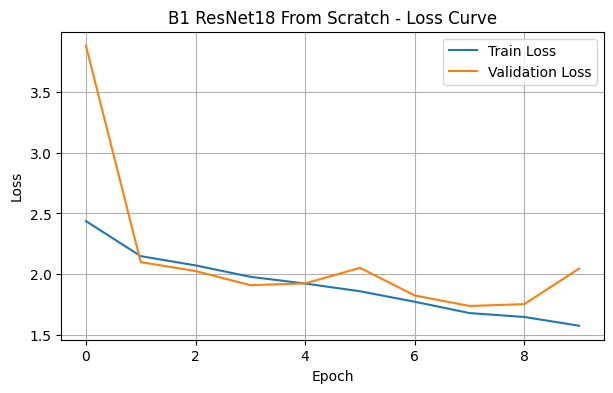

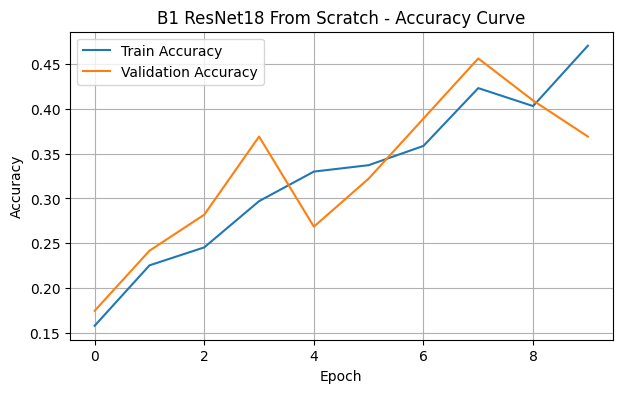

In [40]:
import matplotlib.pyplot as plt


# ============================
# B1 Loss Curve
# ============================

plt.figure(figsize=(7,4))

plt.plot(
    history_B1["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_B1["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "B1 ResNet18 From Scratch - Loss Curve"
)

plt.legend()
plt.grid(True)

plt.show()



# ============================
# B1 Accuracy Curve
# ============================

plt.figure(figsize=(7,4))

plt.plot(
    history_B1["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    history_B1["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "B1 ResNet18 From Scratch - Accuracy Curve"
)

plt.legend()
plt.grid(True)

plt.show()

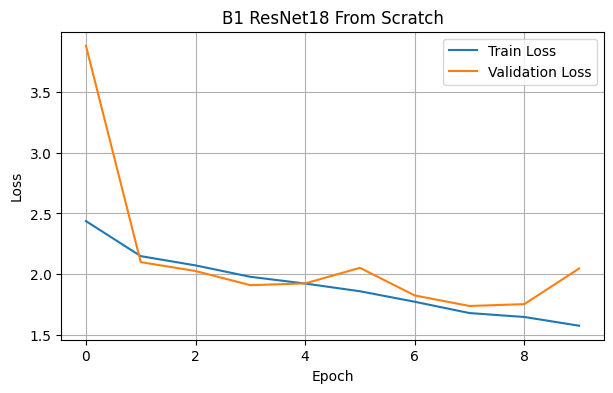

In [41]:
plt.figure(figsize=(7,4))

plt.plot(history_B1["train_loss"], label="Train Loss")
plt.plot(history_B1["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("B1 ResNet18 From Scratch")

plt.legend()
plt.grid(True)

plt.show()

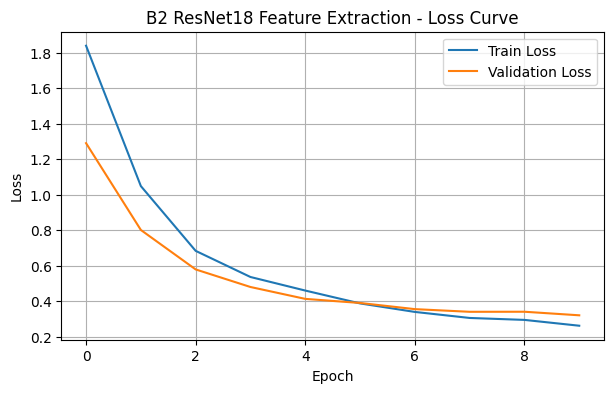

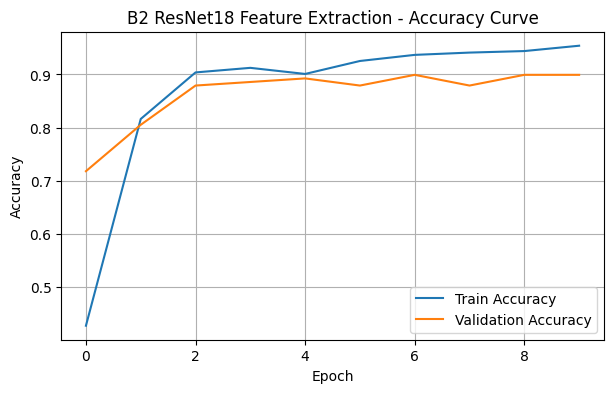

In [42]:
import matplotlib.pyplot as plt



plt.figure(figsize=(7,4))

plt.plot(
    history_B2["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_B2["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "B2 ResNet18 Feature Extraction - Loss Curve"
)

plt.legend()
plt.grid(True)

plt.show()





plt.figure(figsize=(7,4))

plt.plot(
    history_B2["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    history_B2["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "B2 ResNet18 Feature Extraction - Accuracy Curve"
)

plt.legend()
plt.grid(True)

plt.show()

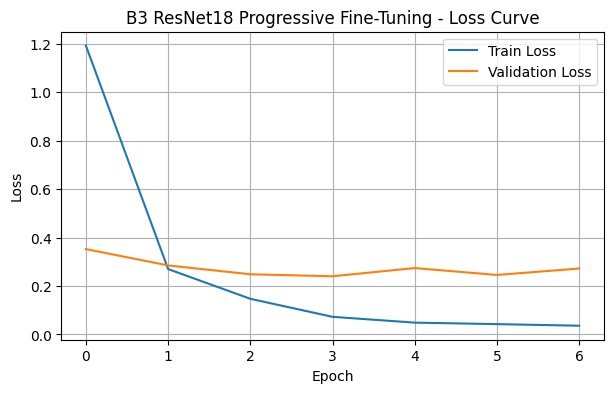

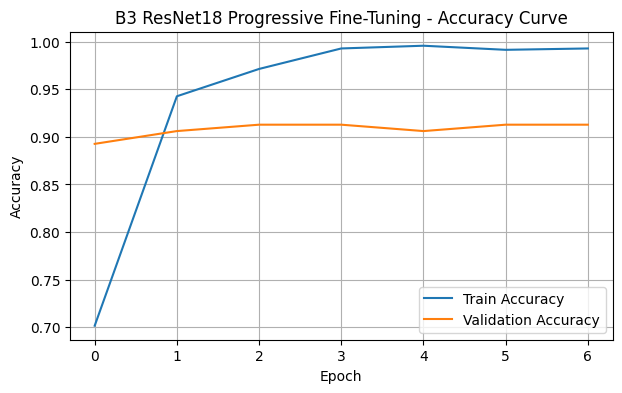

In [43]:
import matplotlib.pyplot as plt


# ============================
# B3 Loss Curve
# ============================

plt.figure(figsize=(7,4))

plt.plot(
    history_B3["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_B3["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "B3 ResNet18 Progressive Fine-Tuning - Loss Curve"
)

plt.legend()
plt.grid(True)

plt.show()





plt.figure(figsize=(7,4))

plt.plot(
    history_B3["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    history_B3["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "B3 ResNet18 Progressive Fine-Tuning - Accuracy Curve"
)

plt.legend()
plt.grid(True)

plt.show()

In [44]:
model_B3.load_state_dict(
    torch.load("best_B3.pth")
)

model_B3.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [45]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report


y_true = []
y_pred = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)


        outputs = model_B3(images)


        preds = torch.argmax(
            outputs,
            dim=1
        )


        y_true.extend(
            labels.cpu().numpy()
        )

        y_pred.extend(
            preds.cpu().numpy()
        )


y_true = np.array(y_true)
y_pred = np.array(y_pred)


print("Jumlah data test:", len(y_true))

Jumlah data test: 150


In [46]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=selected_classes
    )
)

                    precision    recall  f1-score   support

        Abyssinian       0.88      1.00      0.94        15
            Bengal       1.00      1.00      1.00        15
            Birman       1.00      1.00      1.00        15
            Bombay       1.00      1.00      1.00        15
 British Shorthair       1.00      1.00      1.00        15
  American Bulldog       1.00      1.00      1.00        15
            Beagle       1.00      0.87      0.93        15
             Boxer       1.00      1.00      1.00        15
German Shorthaired       1.00      1.00      1.00        15
         Chihuahua       1.00      1.00      1.00        15

          accuracy                           0.99       150
         macro avg       0.99      0.99      0.99       150
      weighted avg       0.99      0.99      0.99       150



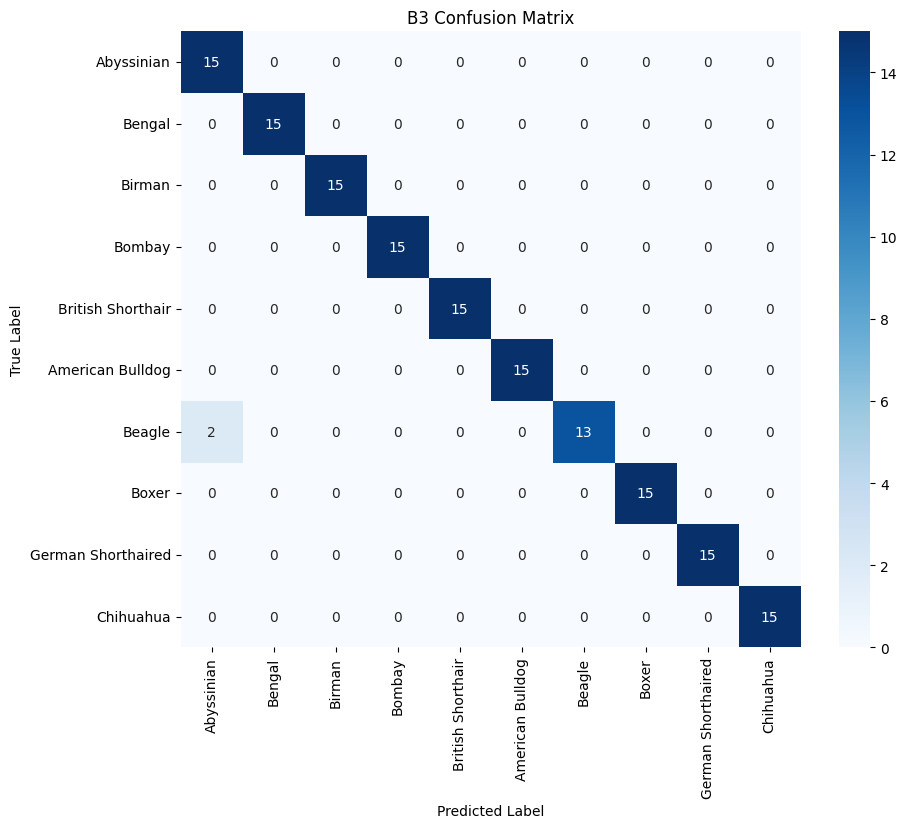

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=selected_classes,
    yticklabels=selected_classes
)


plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("B3 Confusion Matrix")

plt.show()


Jumlah salah prediksi: 2


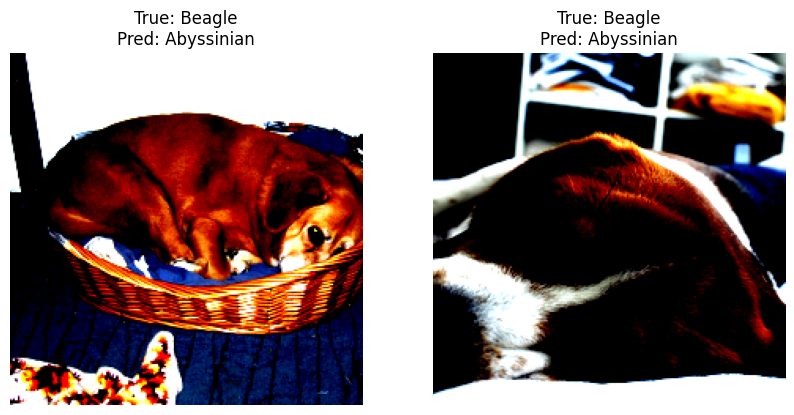

In [48]:
id="failure"
import matplotlib.pyplot as plt


wrong_indices = np.where(
    y_true != y_pred
)[0]


print("Jumlah salah prediksi:", len(wrong_indices))


plt.figure(figsize=(10,5))


for i, idx in enumerate(wrong_indices):

    image, label = test_dataset[idx]

    plt.subplot(1, len(wrong_indices), i+1)

    img = image.permute(1,2,0).numpy()

    plt.imshow(img)

    plt.title(
        f"True: {selected_classes[y_true[idx]]}\nPred: {selected_classes[y_pred[idx]]}"
    )

    plt.axis("off")


plt.show()

In [49]:
from torchvision import transforms


no_aug_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [50]:
no_aug_transform = transforms.Compose([

    transforms.Resize(256),

    transforms.CenterCrop(224),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    )
])

In [51]:
train_dataset_no_aug = PetDataset(
    dataset,
    train_indices,
    train_labels,
    no_aug_transform
)


val_dataset_no_aug = PetDataset(
    dataset,
    val_indices,
    val_labels,
    eval_transform
)


test_dataset_no_aug = PetDataset(
    dataset,
    test_indices,
    test_labels,
    eval_transform
)

In [52]:
train_loader_no_aug = DataLoader(
    train_dataset_no_aug,
    batch_size=32,
    shuffle=True
)


val_loader_no_aug = DataLoader(
    val_dataset_no_aug,
    batch_size=32,
    shuffle=False
)


test_loader_no_aug = DataLoader(
    test_dataset_no_aug,
    batch_size=32,
    shuffle=False
)

In [53]:
model_B4_no_aug = build_model("feature")

In [54]:
history_B4_no_aug = train_model(
    model_B4_no_aug,
    train_loader_no_aug,
    val_loader_no_aug,
    epochs=10,
    save_name="best_B4_no_aug.pth"
)


Epoch 1/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.7464 | Train Acc: 0.4735
Val Loss: 1.1043 | Val Acc: 0.7852

Epoch 2/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.8509 | Train Acc: 0.8838
Val Loss: 0.6678 | Val Acc: 0.8993

Epoch 3/10


...

Train Loss: 0.2095 | Train Acc: 0.9699
Val Loss: 0.3021 | Val Acc: 0.9262

Epoch 9/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.1832 | Train Acc: 0.9699
Val Loss: 0.2843 | Val Acc: 0.9262

Epoch 10/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.1879 | Train Acc: 0.9699
Val Loss: 0.2752 | Val Acc: 0.9128
Training time: 60.70570182800293 seconds


In [55]:
model_B4_aug = build_model("feature")

In [56]:
history_B4_aug = train_model(
    model_B4_aug,
    train_loader,
    val_loader,
    epochs=10,
    save_name="best_B4_aug.pth"
)


Epoch 1/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.9533 | Train Acc: 0.3515
Val Loss: 1.3313 | Val Acc: 0.7181

Epoch 2/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.1442 | Train Acc: 0.7704
Val Loss: 0.8119 | Val Acc: 0.8591

Epoch 3/10


...

Train Loss: 0.3137 | Train Acc: 0.9541
Val Loss: 0.3356 | Val Acc: 0.9060

Epoch 9/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.2941 | Train Acc: 0.9484
Val Loss: 0.2999 | Val Acc: 0.9262

Epoch 10/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.2638 | Train Acc: 0.9555
Val Loss: 0.3086 | Val Acc: 0.8993
Training time: 85.79209041595459 seconds


In [57]:
model_B4_no_aug.load_state_dict(
    torch.load("best_B4_no_aug.pth")
)


loss, acc, f1 = evaluate(
    model_B4_no_aug,
    test_loader_no_aug,
    nn.CrossEntropyLoss()
)

print(acc, f1)

0.98 0.9799777530589544


In [58]:
model_B4_aug.load_state_dict(
    torch.load("best_B4_aug.pth")
)


loss, acc, f1 = evaluate(
    model_B4_aug,
    test_loader,
    nn.CrossEntropyLoss()
)

print(acc, f1)

0.9733333333333334 0.9735052836484982


In [59]:
from torchvision import models
import torch.nn as nn

In [60]:
weights_eff = models.EfficientNet_B0_Weights.IMAGENET1K_V1


model_EFF = models.efficientnet_b0(
    weights=weights_eff
)


# freeze semua backbone

for param in model_EFF.parameters():
    param.requires_grad = False


# ganti classifier

num_features = model_EFF.classifier[1].in_features


model_EFF.classifier[1] = nn.Linear(
    num_features,
    10
)


model_EFF = model_EFF.to(device)

In [61]:
trainable_params = sum(
    p.numel()
    for p in model_EFF.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model_EFF.parameters()
)


print("Trainable Parameters:", trainable_params)
print("Total Parameters:", total_params)

Trainable Parameters: 12810
Total Parameters: 4020358


In [62]:
import time

start = time.time()

history_EFF = train_model(
    model_EFF,
    train_loader,
    val_loader,
    epochs=10,
    save_name="best_EFF.pth"
)

end = time.time()

training_time_EFF = end - start

print("EfficientNet-B0 Training Time:", training_time_EFF, "seconds")


Epoch 1/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.8213 | Train Acc: 0.5466
Val Loss: 1.2563 | Val Acc: 0.8859

Epoch 2/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 1.0922 | Train Acc: 0.8623
Val Loss: 0.8368 | Val Acc: 0.8926

Epoch 3/10


...

Train Loss: 0.3500 | Train Acc: 0.9412
Val Loss: 0.3775 | Val Acc: 0.9195

Epoch 9/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.3152 | Train Acc: 0.9469
Val Loss: 0.3662 | Val Acc: 0.9195

Epoch 10/10


  0%|          | 0/22 [00:00<?, ?it/s]

Train Loss: 0.2853 | Train Acc: 0.9455
Val Loss: 0.3478 | Val Acc: 0.9195
Training time: 88.28966569900513 seconds
EfficientNet-B0 Training Time: 88.29086828231812 seconds


In [63]:
model_EFF.load_state_dict(
    torch.load("best_EFF.pth")
)


test_loss_EFF, test_acc_EFF, test_f1_EFF = evaluate(
    model_EFF,
    test_loader,
    nn.CrossEntropyLoss()
)


print("EFF Test Loss:", test_loss_EFF)
print("EFF Test Accuracy:", test_acc_EFF)
print("EFF Test Macro F1:", test_f1_EFF)

EFF Test Loss: 0.25589710772037505
EFF Test Accuracy: 0.9666666666666667
EFF Test Macro F1: 0.9665923115631125


In [65]:
import os

print(os.listdir())

['.config', 'best_EFF.pth', 'experiment_results.json', 'best_B4_no_aug.pth', 'data', 'best_B1.pth', 'best_B4_aug.pth', 'best_model.pth', 'best_B2.pth', 'best_B3.pth', 'sample_data']


In [66]:
import json

with open("experiment_results.json") as f:
    data = json.load(f)

data

{'dataset': {'name': 'OxfordIIITPet',
  'selected_classes': 10,
  'total_images': 996,
  'train_images': 697,
  'val_images': 149,
  'test_images': 150},
 'experiments': {'B1_ResNet18_Scratch': {'strategy': 'From Scratch',
   'total_parameters': 11181642,
   'trainable_parameters': 11181642,
   'learning_rate': 0.001,
   'epochs': 10,
   'training_time_seconds': 98.27,
   'best_val_accuracy': 0.4027,
   'test_loss': 1.8331,
   'test_accuracy': 0.36,
   'test_macro_f1': 0.3395},
  'B2_ResNet18_Feature_Extraction': {'strategy': 'Feature Extraction',
   'total_parameters': 11181642,
   'trainable_parameters': 5130,
   'learning_rate': 0.001,
   'epochs': 10,
   'training_time_seconds': 89.92,
   'best_val_accuracy': 0.8993,
   'test_loss': 0.2055,
   'test_accuracy': 0.9867,
   'test_macro_f1': 0.9867},
  'B3_ResNet18_Progressive_Fine_Tuning': {'strategy': 'Progressive Fine-Tuning',
   'total_parameters': 11181642,
   'trainable_parameters': 8398858,
   'learning_rate': {'layer4': 0.0001,